Range of sigma values used: [2.00, 30.00] (15 scales)
Total circles detected: 508

Top 5 Largest Circles (x, y, sigma, radius):
  1. Center=(234, 0), sigma=30.00, radius=42.43 px
  2. Center=(0, 53), sigma=30.00, radius=42.43 px
  3. Center=(106, 143), sigma=30.00, radius=42.43 px
  4. Center=(0, 142), sigma=24.72, radius=34.96 px
  5. Center=(96, 144), sigma=24.72, radius=34.96 px


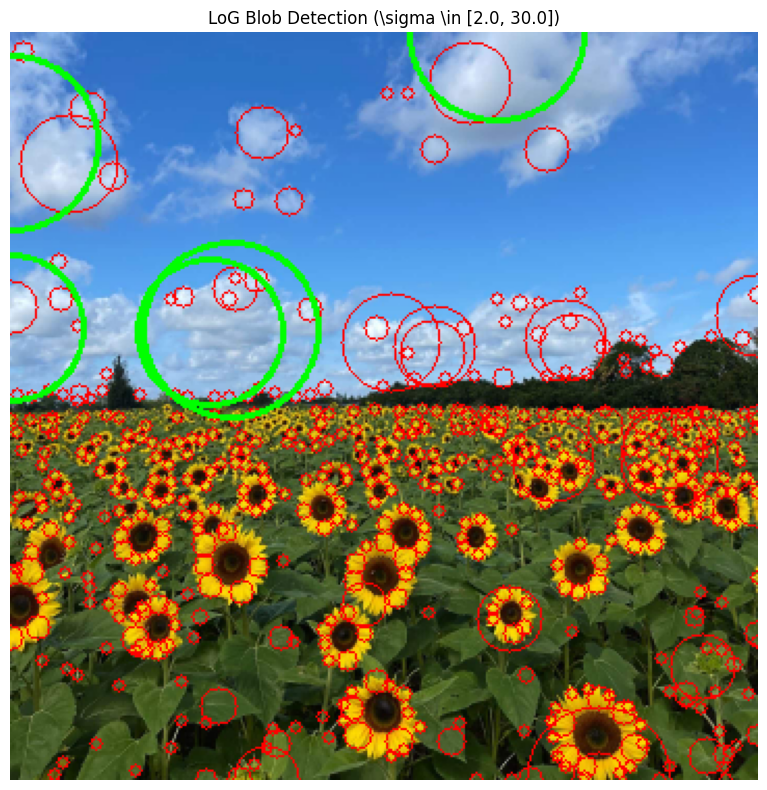

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

# 1. Load image as specified in the assignment
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError("Make sure 'the_berry_farms_sunflower_field.jpeg' is inside the 'images/' folder.")

# Convert to grayscale and normalize to [0, 1]
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0

# Invert image if detecting dark centers on bright backgrounds, or keep as is for bright blobs.
# Using squared/absolute normalized LoG detects both bright and dark blobs.
num_scales = 15
sigma_min, sigma_max = 2.0, 30.0
sigmas = np.geomspace(sigma_min, sigma_max, num_scales)

# 2. Build Scale-Space Volume (Scale-normalized LoG)
# Multiply by sigma^2 for scale invariance
scale_space = np.empty((gray.shape[0], gray.shape[1], num_scales))
for i, s in enumerate(sigmas):
    # -gaussian_laplace gives positive peaks for bright blobs on dark background
    log_response = - (s ** 2) * gaussian_laplace(gray, sigma=s)
    scale_space[:, :, i] = log_response

# 3. 3D Non-Maximum Suppression (Scale-space extrema detection)
threshold = 0.08  # Adjust slightly (e.g., 0.05 to 0.12) depending on image contrast
local_max = maximum_filter(scale_space, size=(5, 5, 3))
extrema = (scale_space == local_max) & (scale_space > threshold)

# Extract coordinates (y, x, scale_index)
y_coords, x_coords, s_indices = np.where(extrema)
radii = np.sqrt(2) * sigmas[s_indices]
responses = scale_space[y_coords, x_coords, s_indices]

# Sort blobs by radius (largest first)
sorted_idx = np.argsort(-radii)
y_coords = y_coords[sorted_idx]
x_coords = x_coords[sorted_idx]
radii = radii[sorted_idx]
best_sigmas = sigmas[s_indices[sorted_idx]]
responses = responses[sorted_idx]

# 4. Report parameters
print(f"Range of sigma values used: [{sigma_min:.2f}, {sigma_max:.2f}] ({num_scales} scales)")
print(f"Total circles detected: {len(radii)}\n")
print("Top 5 Largest Circles (x, y, sigma, radius):")
for i in range(min(5, len(radii))):
    print(f"  {i+1}. Center=({x_coords[i]}, {y_coords[i]}), sigma={best_sigmas[i]:.2f}, radius={radii[i]:.2f} px")

# 5. Draw circles on the image
im_out = cv.cvtColor(im, cv.COLOR_BGR2RGB)
for x, y, r in zip(x_coords, y_coords, radii):
    cv.circle(im_out, (int(x), int(y)), int(round(r)), (255, 0, 0), 1)

# Highlight the top 5 largest circles in green
for i in range(min(5, len(radii))):
    cv.circle(im_out, (int(x_coords[i]), int(y_coords[i])), int(round(radii[i])), (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(im_out)
plt.title(f"LoG Blob Detection (\sigma \in [{sigma_min}, {sigma_max}])")
plt.axis('off')
plt.tight_layout()
plt.savefig('q1_result.png', dpi=300)
plt.show()